In [30]:
"""
CASE STUDY: AI-Powered E-Commerce Intelligence Platform (BALANCED VERSION)
============================================================================
"""

import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU(s) detected: {len(gpus)} -> {gpus}")
if not gpus:
    print("WARNING: No GPU detected -- sections F and G will be noticeably slower.")
    print("In Colab: Runtime > Change runtime type > Hardware accelerator > GPU.")

TOP_N_CLASSES = 10
IMAGES_PER_CLASS_CAP = 600     # caps F/G data so runtime stays reasonable
PERCEPTRON_IMG_SIZE = 28
CNN_IMG_SIZE = 96
TRANSFER_IMG_SIZE = 128
BATCH_SIZE = 32

GPU(s) detected: 0 -> []
In Colab: Runtime > Change runtime type > Hardware accelerator > GPU.


In [32]:
# =====================================================================
# A. DATA INGESTION & PREPARATION
# =====================================================================
print("=" * 70)
print("A. DATA INGESTION — Fashion Product Images (Small)")
print("=" * 70)

# In Colab, first upload your kaggle.json, then:
#   from google.colab import files
#   files.upload()
#   os.makedirs("/root/.kaggle", exist_ok=True)
#   os.rename("kaggle.json", "/root/.kaggle/kaggle.json")
#   os.chmod("/root/.kaggle/kaggle.json", 0o600)
os.system("kaggle datasets download -d paramaggarwal/fashion-product-images-small -p ./data --unzip")

DATA_DIR = "./data"
IMAGE_DIR = os.path.join(DATA_DIR, "images")
STYLES_CSV = os.path.join(DATA_DIR, "styles.csv")

print("Loading and cleaning product metadata")
df = pd.read_csv(STYLES_CSV, on_bad_lines="skip")
df = df.dropna(subset=["masterCategory", "articleType", "baseColour",
                        "season", "usage", "year", "gender", "subCategory"])
df["image_path"] = df["id"].astype(str).apply(lambda x: os.path.join(IMAGE_DIR, f"{x}.jpg"))
df = df[df["image_path"].apply(os.path.exists)].reset_index(drop=True)
print(f"  Usable products after cleaning: {len(df)}")

top_types = df["articleType"].value_counts().nlargest(TOP_N_CLASSES).index.tolist()
df_top = df[df["articleType"].isin(top_types)].reset_index(drop=True)
article_encoder = LabelEncoder()
df_top["label"] = article_encoder.fit_transform(df_top["articleType"])
print(f"  Using top {TOP_N_CLASSES} article types: {top_types}")
print(f"  Metadata dataset (used by B/C/D/E): {len(df_top)} products")

# Capped, class-balanced subset for the image-heavy sections (F/G) --
# still a real, representative sample, just bounded for runtime.
img_subset = (df_top.groupby("articleType", group_keys=False)
              .apply(lambda g: g.sample(n=min(len(g), IMAGES_PER_CLASS_CAP), random_state=SEED)))
img_subset = img_subset.reset_index(drop=True)
print(f"  Image dataset (used by F/G): {len(img_subset)} products "
      f"(~{IMAGES_PER_CLASS_CAP} per class cap)")

train_df, temp_df = train_test_split(img_subset, test_size=0.30, stratify=img_subset["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
print(f"  Image split -> train: {len(train_df)} | val: {len(val_df)} | test: {len(test_df)}")

A. DATA INGESTION — Fashion Product Images (Small)
Loading and cleaning product metadata
  Usable products after cleaning: 44074
  Using top 10 article types: ['Tshirts', 'Shirts', 'Casual Shoes', 'Watches', 'Sports Shoes', 'Kurtas', 'Tops', 'Handbags', 'Heels', 'Sunglasses']
  Metadata dataset (used by B/C/D/E): 25441 products
  Image dataset (used by F/G): 6000 products (~600 per class cap)
  Image split -> train: 4200 | val: 900 | test: 900


/tmp/ipykernel_7737/2220766945.py:38: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), IMAGES_PER_CLASS_CAP), random_state=SEED)))



B. Perceptron — Business Rules & Product-Image Binary Classifier
  AND gate: target=[0, 0, 0, 1]  learned=[0, 0, 0, 1]
  OR gate: target=[0, 1, 1, 1]  learned=[0, 1, 1, 1]
  Class balance: {'Topwear': 15383, 'Bottomwear': 2685}
  Using 5000 images for the perceptron (capped, balanced)


/tmp/ipykernel_7737/2470558681.py:52: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), 2500), random_state=SEED)))


  Perceptron accuracy (Topwear vs Bottomwear): 0.9700
              precision    recall  f1-score   support

     Topwear       0.99      0.95      0.97       500
  Bottomwear       0.96      0.99      0.97       500

    accuracy                           0.97      1000
   macro avg       0.97      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



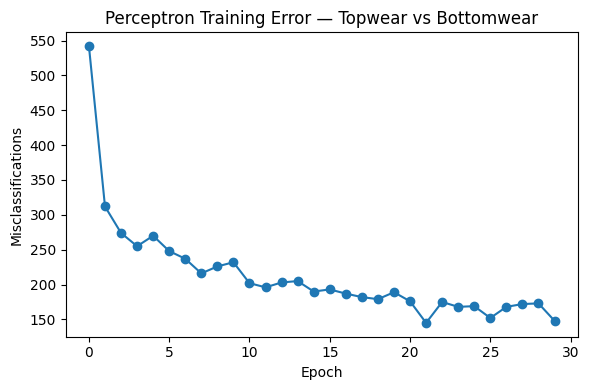

In [33]:
# =====================================================================
# B. ORDER-ELIGIBILITY RULE ENGINE + PRODUCT-IMAGE GATE CLASSIFIER
#    (Perceptron)
# =====================================================================
print("\n" + "=" * 70)
print("B. Perceptron — Business Rules & Product-Image Binary Classifier")
print("=" * 70)

class Perceptron:
    def __init__(self, n_inputs, lr=0.1, epochs=30):
        self.w = np.zeros(n_inputs)
        self.b = 0.0
        self.lr = lr
        self.epochs = epochs
        self.error_history = []

    def activation(self, x):
        return 1 if x >= 0 else 0

    def predict(self, x):
        return self.activation(np.dot(self.w, x) + self.b)

    def fit(self, X, y):
        for epoch in range(self.epochs):
            total_error = 0
            for xi, target in zip(X, y):
                pred = self.predict(xi)
                error = target - pred
                self.w += self.lr * error * xi
                self.b += self.lr * error
                total_error += abs(error)
            self.error_history.append(total_error)
            if total_error == 0:
                break
        return self

# --- B1. Business rule gates ---
X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": np.array([0, 0, 0, 1]), "OR": np.array([0, 1, 1, 1])}
for gname, gy in gates.items():
    gp = Perceptron(n_inputs=2, lr=0.1, epochs=20).fit(X_bool, gy)
    print(f"  {gname} gate: target={gy.tolist()}  learned={[gp.predict(xi) for xi in X_bool]}")

# --- B2. Real product-image binary classifier: Topwear vs Bottomwear ---
# Draws from the FULL cleaned dataset (df), not df_top, so both classes
# are guaranteed to be meaningfully represented (df_top's top-10 article
# types can otherwise skew heavily toward one subCategory).
subcat_df = df[df["subCategory"].isin(["Topwear", "Bottomwear"])].reset_index(drop=True)
print(f"  Class balance: {subcat_df['subCategory'].value_counts().to_dict()}")
# Cap for runtime -- still thousands of images, balanced across classes
subcat_df = (subcat_df.groupby("subCategory", group_keys=False)
             .apply(lambda g: g.sample(n=min(len(g), 2500), random_state=SEED)))
subcat_df = subcat_df.reset_index(drop=True)
print(f"  Using {len(subcat_df)} images for the perceptron (capped, balanced)")

def load_gray_flat(path, size=PERCEPTRON_IMG_SIZE):
    img = keras.utils.load_img(path, color_mode="grayscale", target_size=(size, size))
    return keras.utils.img_to_array(img).flatten() / 255.0

Xb = np.stack([load_gray_flat(p) for p in subcat_df["image_path"]])
yb = (subcat_df["subCategory"] == "Bottomwear").astype(int).values
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=SEED)

img_perceptron = Perceptron(n_inputs=Xb.shape[1], lr=0.001, epochs=30)
img_perceptron.fit(Xb_train, yb_train)
img_preds = [img_perceptron.predict(xi) for xi in Xb_test]
img_acc = np.mean(np.array(img_preds) == yb_test)
print(f"  Perceptron accuracy (Topwear vs Bottomwear): {img_acc:.4f}")
print(classification_report(yb_test, img_preds, target_names=["Topwear", "Bottomwear"]))

plt.figure(figsize=(6, 4))
plt.plot(img_perceptron.error_history, marker="o")
plt.title("Perceptron Training Error — Topwear vs Bottomwear")
plt.xlabel("Epoch"); plt.ylabel("Misclassifications")
plt.tight_layout()
plt.savefig("B_perceptron_error_curve.png")
plt.show()


C. MLP — Product Category Classifier & Product-Year Estimator
Epoch 1/40
271/271 - 7s - 26ms/step - accuracy: 0.4748 - loss: 1.4656 - val_accuracy: 0.6004 - val_loss: 1.0030
Epoch 2/40
271/271 - 1s - 5ms/step - accuracy: 0.6009 - loss: 0.9677 - val_accuracy: 0.6145 - val_loss: 0.9485
Epoch 3/40
271/271 - 3s - 9ms/step - accuracy: 0.6082 - loss: 0.9351 - val_accuracy: 0.6207 - val_loss: 0.9374
Epoch 4/40
271/271 - 2s - 8ms/step - accuracy: 0.6112 - loss: 0.9238 - val_accuracy: 0.6207 - val_loss: 0.9342
Epoch 5/40
271/271 - 3s - 10ms/step - accuracy: 0.6125 - loss: 0.9174 - val_accuracy: 0.6178 - val_loss: 0.9320
Epoch 6/40
271/271 - 1s - 5ms/step - accuracy: 0.6127 - loss: 0.9139 - val_accuracy: 0.6174 - val_loss: 0.9316
Epoch 7/40
271/271 - 2s - 9ms/step - accuracy: 0.6118 - loss: 0.9104 - val_accuracy: 0.6174 - val_loss: 0.9310
Epoch 8/40
271/271 - 1s - 3ms/step - accuracy: 0.6126 - loss: 0.9082 - val_accuracy: 0.6187 - val_loss: 0.9308
Epoch 9/40
271/271 - 1s - 2ms/step - accuracy: 

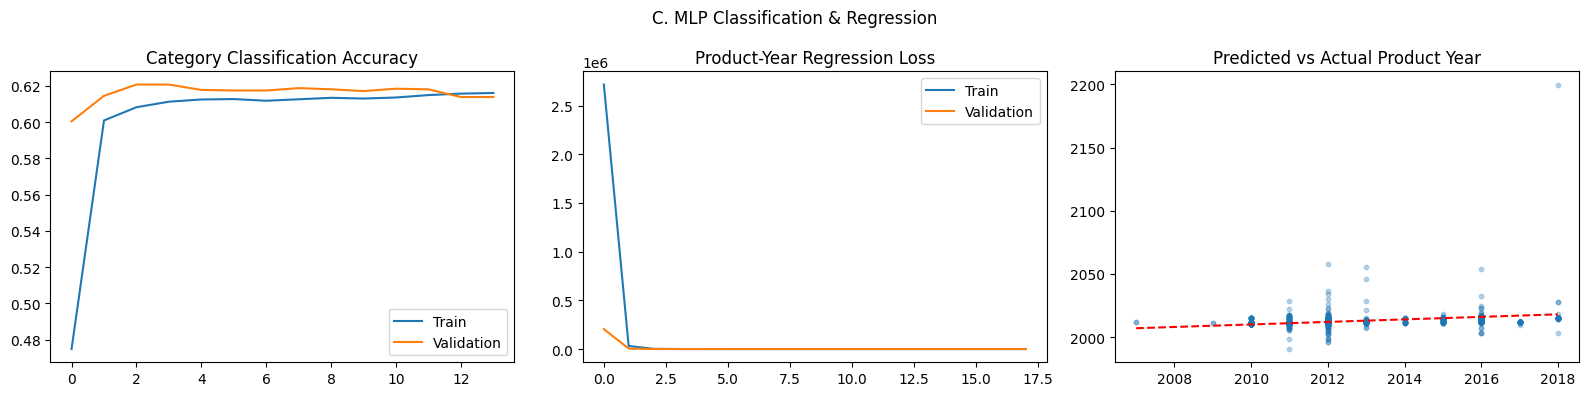

In [34]:
# =====================================================================
# C. PRODUCT CATEGORY CLASSIFIER + PRODUCT-YEAR ESTIMATOR (MLP)
# =====================================================================
print("\n" + "=" * 70)
print("C. MLP — Product Category Classifier & Product-Year Estimator")
print("=" * 70)

feature_cols = ["gender", "baseColour", "season", "usage"]
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_meta = ohe.fit_transform(df_top[feature_cols].astype(str))
y_class = df_top["label"].values
y_year = df_top["year"].values.astype("float32")
X_meta_scaled = StandardScaler(with_mean=False).fit_transform(X_meta)

Xtr, Xte, ytr, yte = train_test_split(X_meta_scaled, y_class, test_size=0.2,
                                       stratify=y_class, random_state=SEED)

def build_classifier(input_dim):
    return keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(len(top_types), activation="softmax"),
    ])

es_generic = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

clf_model = build_classifier(X_meta.shape[1])
clf_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
clf_history = clf_model.fit(Xtr, ytr, epochs=40, batch_size=64, validation_split=0.15,
                             callbacks=[es_generic], verbose=2)
_, clf_acc = clf_model.evaluate(Xte, yte, verbose=0)
print(f"  Category classification test accuracy: {clf_acc:.4f}")

Xtr_y, Xte_y, ytr_y, yte_y = train_test_split(X_meta_scaled, y_year, test_size=0.2, random_state=SEED)
reg_model = keras.Sequential([
    layers.Input(shape=(X_meta.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="linear"),
])
reg_model.compile(optimizer="adam", loss="mse", metrics=["mae"])
reg_history = reg_model.fit(Xtr_y, ytr_y, epochs=40, batch_size=64, validation_split=0.15,
                             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6,
                                                                      restore_best_weights=True)],
                             verbose=2)
_, year_mae = reg_model.evaluate(Xte_y, yte_y, verbose=0)
print(f"  Product-year regression test MAE: {year_mae:.2f} years")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(clf_history.history["accuracy"], label="Train")
axes[0].plot(clf_history.history["val_accuracy"], label="Validation")
axes[0].set_title("Category Classification Accuracy"); axes[0].legend()
axes[1].plot(reg_history.history["loss"], label="Train")
axes[1].plot(reg_history.history["val_loss"], label="Validation")
axes[1].set_title("Product-Year Regression Loss"); axes[1].legend()
y_pred_year = reg_model.predict(Xte_y, verbose=0).flatten()
axes[2].scatter(yte_y, y_pred_year, alpha=0.3, s=10)
axes[2].plot([yte_y.min(), yte_y.max()], [yte_y.min(), yte_y.max()], "r--")
axes[2].set_title("Predicted vs Actual Product Year")
plt.suptitle("C. MLP Classification & Regression")
plt.tight_layout()
plt.savefig("C_mlp_results.png")
plt.show()


D. Optimizer Comparison for the Category Classifier
  Training with SGD (plain GD) ...
    Test accuracy: 0.6176
  Training with Momentum ...
    Test accuracy: 0.6129
  Training with RMSProp ...
    Test accuracy: 0.6154
  Training with Adam ...
    Test accuracy: 0.6158


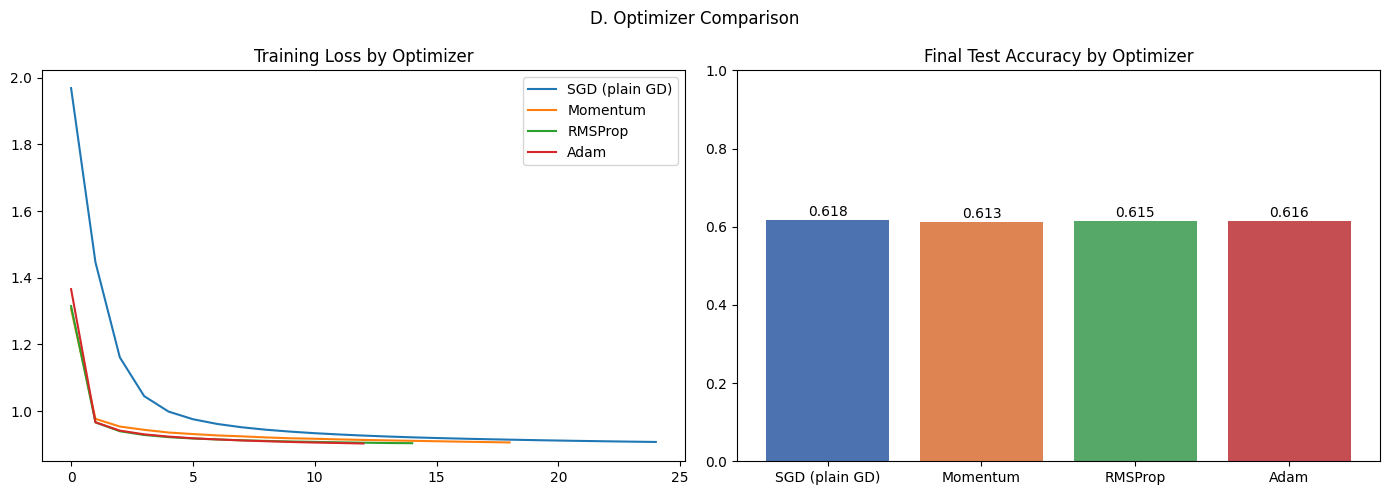

In [35]:
# =====================================================================
# D. TRAINING-STRATEGY COMPARISON (Optimizers)
# =====================================================================
print("\n" + "=" * 70)
print("D. Optimizer Comparison for the Category Classifier")
print("=" * 70)

optimizers = {
    "SGD (plain GD)": keras.optimizers.SGD(learning_rate=0.01),
    "Momentum":       keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSProp":        keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam":           keras.optimizers.Adam(learning_rate=0.001),
}
opt_histories, opt_scores = {}, {}
for name, opt in optimizers.items():
    print(f"  Training with {name} ...")
    model = build_classifier(X_meta.shape[1])
    model.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = model.fit(Xtr, ytr, epochs=25, batch_size=64, validation_split=0.15,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6,
                                                                restore_best_weights=True)],
                      verbose=0)
    _, acc = model.evaluate(Xte, yte, verbose=0)
    opt_histories[name] = hist.history["loss"]
    opt_scores[name] = acc
    print(f"    Test accuracy: {acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, loss_curve in opt_histories.items():
    axes[0].plot(loss_curve, label=name)
axes[0].set_title("Training Loss by Optimizer"); axes[0].legend()
bars = axes[1].bar(list(opt_scores.keys()), list(opt_scores.values()),
                    color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])
axes[1].set_title("Final Test Accuracy by Optimizer"); axes[1].set_ylim(0, 1)
for bar, acc in zip(bars, opt_scores.values()):
    axes[1].text(bar.get_x() + bar.get_width() / 2, acc + 0.01, f"{acc:.3f}", ha="center")
plt.suptitle("D. Optimizer Comparison")
plt.tight_layout()
plt.savefig("D_optimizer_comparison.png")
plt.show()


E. Regularization for the Category Classifier
  Baseline    -> Train acc: 0.6625 | Val acc: 0.5250
  Regularized -> Val acc: 0.5625 | Test acc: 0.5610


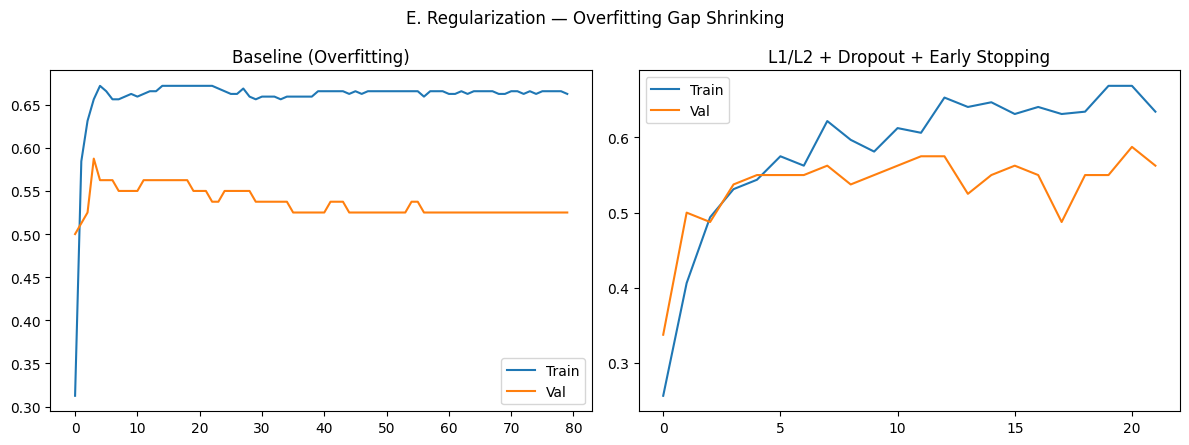


  Hyperparameter tuning over (l2_lambda, dropout_rate):
    l2=0.0001, dropout=0.3 -> val_acc=0.5625
    l2=0.0001, dropout=0.5 -> val_acc=0.5500
    l2=0.001, dropout=0.3 -> val_acc=0.6125
    l2=0.001, dropout=0.5 -> val_acc=0.5750
  Best config: l2=0.001, dropout=0.3 -> val_acc=0.6125


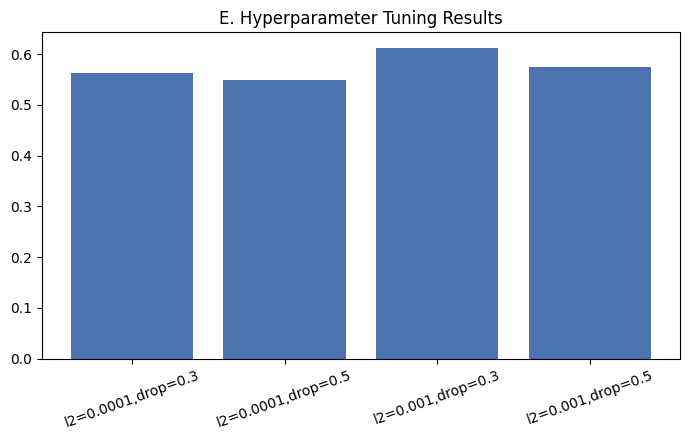

In [36]:
# =====================================================================
# E. OVERFITTING CONTROL (Regularization)
# =====================================================================
print("\n" + "=" * 70)
print("E. Regularization for the Category Classifier")
print("=" * 70)

Xtr_small, ytr_small = Xtr[:400], ytr[:400]

baseline = keras.Sequential([
    layers.Input(shape=(X_meta.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(len(top_types), activation="softmax"),
])
baseline.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = baseline.fit(Xtr_small, ytr_small, epochs=80, batch_size=16, validation_split=0.2, verbose=0)
print(f"  Baseline    -> Train acc: {h1.history['accuracy'][-1]:.4f} | Val acc: {h1.history['val_accuracy'][-1]:.4f}")

reg_l2 = keras.Sequential([
    layers.Input(shape=(X_meta.shape[1],)),
    layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-3)),
    layers.Dropout(0.4),
    layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-3)),
    layers.Dropout(0.4),
    layers.Dense(len(top_types), activation="softmax"),
])
reg_l2.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
es_callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
h2 = reg_l2.fit(Xtr_small, ytr_small, epochs=120, batch_size=16, validation_split=0.2,
                callbacks=[es_callback], verbose=0)
_, reg_test_acc = reg_l2.evaluate(Xte, yte, verbose=0)
print(f"  Regularized -> Val acc: {h2.history['val_accuracy'][-1]:.4f} | Test acc: {reg_test_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(h1.history["accuracy"], label="Train"); axes[0].plot(h1.history["val_accuracy"], label="Val")
axes[0].set_title("Baseline (Overfitting)"); axes[0].legend()
axes[1].plot(h2.history["accuracy"], label="Train"); axes[1].plot(h2.history["val_accuracy"], label="Val")
axes[1].set_title("L1/L2 + Dropout + Early Stopping"); axes[1].legend()
plt.suptitle("E. Regularization — Overfitting Gap Shrinking")
plt.tight_layout()
plt.savefig("E_regularization_stages.png")
plt.show()

print("\n  Hyperparameter tuning over (l2_lambda, dropout_rate):")
best_acc, best_cfg, grid_results = 0, None, {}
for l2_lambda in [1e-4, 1e-3]:
    for dropout_rate in [0.3, 0.5]:
        model = keras.Sequential([
            layers.Input(shape=(X_meta.shape[1],)),
            layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(l2_lambda)),
            layers.Dropout(dropout_rate),
            layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(l2_lambda)),
            layers.Dropout(dropout_rate),
            layers.Dense(len(top_types), activation="softmax"),
        ])
        model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        hist = model.fit(Xtr_small, ytr_small, epochs=50, batch_size=16, validation_split=0.2,
                          callbacks=[es_callback], verbose=0)
        val_acc = max(hist.history["val_accuracy"])
        grid_results[f"l2={l2_lambda},drop={dropout_rate}"] = val_acc
        print(f"    l2={l2_lambda}, dropout={dropout_rate} -> val_acc={val_acc:.4f}")
        if val_acc > best_acc:
            best_acc, best_cfg = val_acc, (l2_lambda, dropout_rate)
print(f"  Best config: l2={best_cfg[0]}, dropout={best_cfg[1]} -> val_acc={best_acc:.4f}")

plt.figure(figsize=(7, 4.5))
plt.bar(list(grid_results.keys()), list(grid_results.values()), color="#4C72B0")
plt.title("E. Hyperparameter Tuning Results")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("E_hyperparameter_grid.png")
plt.show()


# =====================================================================
# tf.data PIPELINE HELPER — shared by sections F and G
# =====================================================================
def make_image_dataset(dataframe, image_size, batch_size=BATCH_SIZE,
                        preprocess_fn=None, augment=False, shuffle=True, cache_name=None):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].values.astype("int32")

    def _load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, (image_size, image_size))
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)

    if cache_name:
        os.makedirs("./tf_cache", exist_ok=True)
        ds = ds.cache(f"./tf_cache/{cache_name}")

    if augment:
        augmenter = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.RandomZoom(0.1),
        ])
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)

    if preprocess_fn is not None:
        ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(dataframe), 4000), seed=SEED)

    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


F. CNN — Product Photo Classifier (from scratch)
Epoch 1/20
132/132 - 100s - 755ms/step - accuracy: 0.1183 - loss: 2.2947 - val_accuracy: 0.1644 - val_loss: 2.1900
Epoch 2/20
132/132 - 139s - 1s/step - accuracy: 0.2490 - loss: 1.9361 - val_accuracy: 0.3389 - val_loss: 1.5596
Epoch 3/20
132/132 - 96s - 726ms/step - accuracy: 0.3305 - loss: 1.6401 - val_accuracy: 0.3689 - val_loss: 1.5276
Epoch 4/20
132/132 - 152s - 1s/step - accuracy: 0.3967 - loss: 1.5133 - val_accuracy: 0.4678 - val_loss: 1.3271
Epoch 5/20
132/132 - 101s - 761ms/step - accuracy: 0.4319 - loss: 1.4244 - val_accuracy: 0.4822 - val_loss: 1.2768
Epoch 6/20
132/132 - 143s - 1s/step - accuracy: 0.4764 - loss: 1.3266 - val_accuracy: 0.5311 - val_loss: 1.2031
Epoch 7/20
132/132 - 132s - 997ms/step - accuracy: 0.4974 - loss: 1.2849 - val_accuracy: 0.4567 - val_loss: 1.3246
Epoch 8/20
132/132 - 142s - 1s/step - accuracy: 0.5307 - loss: 1.2036 - val_accuracy: 0.5933 - val_loss: 1.1314
Epoch 9/20
132/132 - 144s - 1s/step - accur

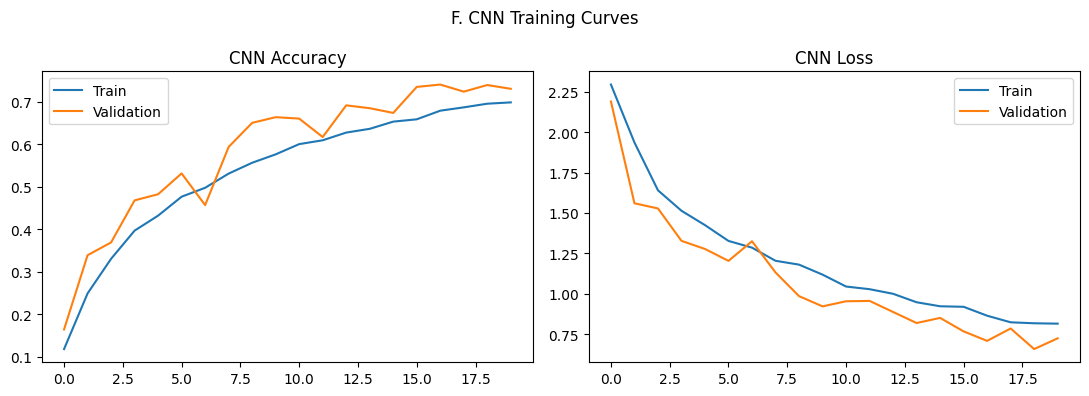

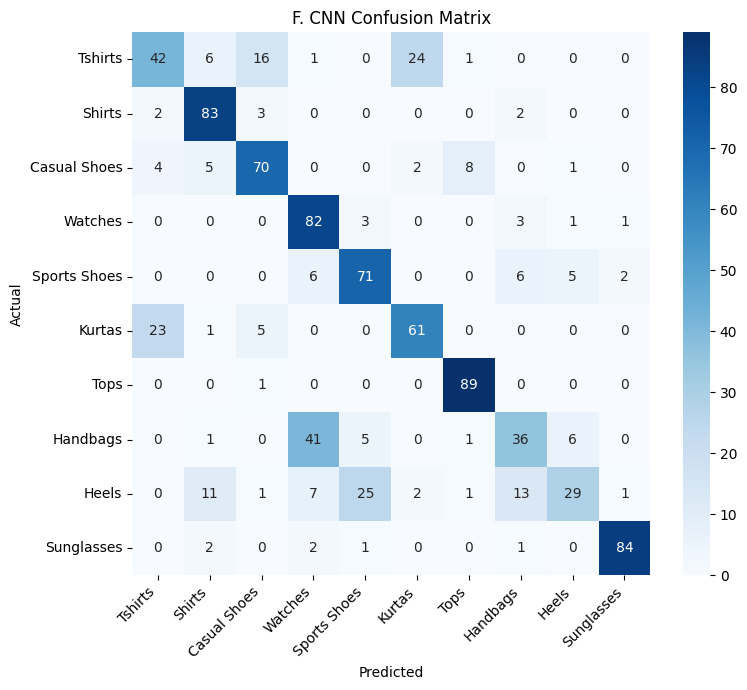

In [37]:
# =====================================================================
# F. PRODUCT-PHOTO CLASSIFIER FROM SCRATCH (CNN)
# =====================================================================
print("\n" + "=" * 70)
print("F. CNN — Product Photo Classifier (from scratch)")
print("=" * 70)

train_ds_cnn = make_image_dataset(train_df, CNN_IMG_SIZE, augment=True, shuffle=True,
                                   cache_name=f"cnn_train_{CNN_IMG_SIZE}")
val_ds_cnn = make_image_dataset(val_df, CNN_IMG_SIZE, augment=False, shuffle=False,
                                 cache_name=f"cnn_val_{CNN_IMG_SIZE}")
test_ds_cnn = make_image_dataset(test_df, CNN_IMG_SIZE, augment=False, shuffle=False,
                                  cache_name=f"cnn_test_{CNN_IMG_SIZE}")

cnn_model = keras.Sequential([
    layers.Input(shape=(CNN_IMG_SIZE, CNN_IMG_SIZE, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(top_types), activation="softmax"),
])
cnn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cnn_callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]
cnn_history = cnn_model.fit(train_ds_cnn, validation_data=val_ds_cnn, epochs=20,
                             callbacks=cnn_callbacks, verbose=2)
cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_ds_cnn, verbose=0)
print(f"  From-scratch CNN test accuracy: {cnn_test_acc:.4f}")

y_true_cnn = np.concatenate([y.numpy() for _, y in test_ds_cnn])
y_pred_cnn = np.argmax(cnn_model.predict(test_ds_cnn, verbose=0), axis=1)
print(classification_report(y_true_cnn, y_pred_cnn, target_names=top_types))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cnn_history.history["accuracy"], label="Train")
axes[0].plot(cnn_history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy"); axes[0].legend()
axes[1].plot(cnn_history.history["loss"], label="Train")
axes[1].plot(cnn_history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss"); axes[1].legend()
plt.suptitle("F. CNN Training Curves")
plt.tight_layout()
plt.savefig("F_cnn_training_curves.png")
plt.show()

cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn)
plt.figure(figsize=(8, 7))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Blues", xticklabels=top_types, yticklabels=top_types)
plt.title("F. CNN Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("F_cnn_confusion_matrix.png")
plt.show()


G. Transfer Learning — VGG16 & ResNet50 (frozen base)
  Training VGG16 (frozen base) ...
Epoch 1/10
132/132 - 974s - 7s/step - accuracy: 0.6662 - loss: 1.3078 - val_accuracy: 0.8611 - val_loss: 0.4069
Epoch 2/10
132/132 - 970s - 7s/step - accuracy: 0.8088 - loss: 0.5224 - val_accuracy: 0.8767 - val_loss: 0.3574
Epoch 3/10
132/132 - 961s - 7s/step - accuracy: 0.8543 - loss: 0.3946 - val_accuracy: 0.8844 - val_loss: 0.3379
Epoch 4/10
132/132 - 961s - 7s/step - accuracy: 0.8614 - loss: 0.3593 - val_accuracy: 0.8833 - val_loss: 0.3479
Epoch 5/10
132/132 - 904s - 7s/step - accuracy: 0.8793 - loss: 0.3135 - val_accuracy: 0.8933 - val_loss: 0.3272
Epoch 6/10
132/132 - 940s - 7s/step - accuracy: 0.8826 - loss: 0.2944 - val_accuracy: 0.9100 - val_loss: 0.2926
Epoch 7/10
132/132 - 946s - 7s/step - accuracy: 0.9007 - loss: 0.2574 - val_accuracy: 0.9067 - val_loss: 0.2867
Epoch 8/10
132/132 - 934s - 7s/step - accuracy: 0.9060 - loss: 0.2523 - val_accuracy: 0.9011 - val_loss: 0.2986
Epoch 9/10
132

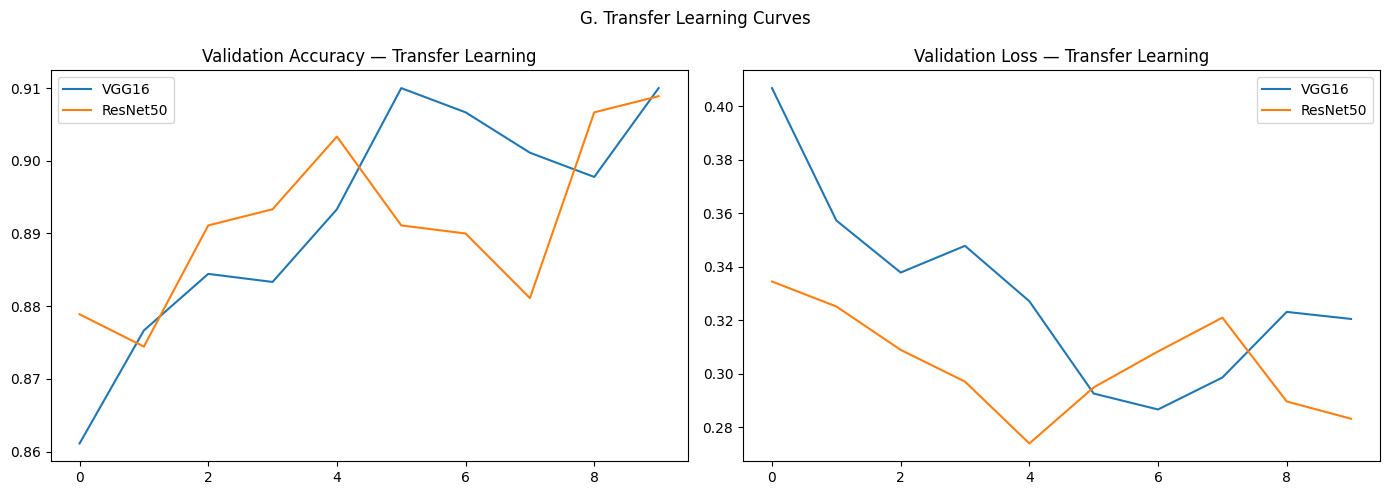

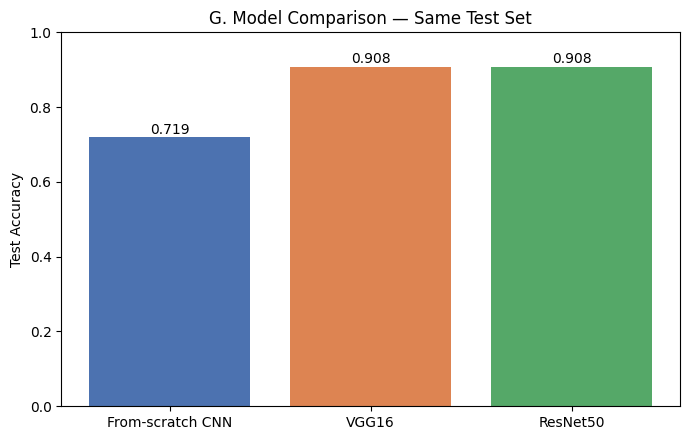


E-COMMERCE INTELLIGENCE PLATFORM — COMPONENT SUMMARY
B. Perceptron    : Topwear-vs-Bottomwear acc = 0.9700
C. MLP           : category acc = 0.6119 | year MAE = 0.86
D. Optimizers    : {'SGD (plain GD)': 0.6176065802574158, 'Momentum': 0.6128905415534973, 'RMSProp': 0.615445077419281, 'Adam': 0.6158381104469299}
E. Regularized   : test acc = 0.5610 | best grid val_acc = 0.6125 (0.001, 0.3)
F. CNN (scratch) : test acc = 0.7189
G. VGG16       : test acc = 0.9078
G. ResNet50    : test acc = 0.9078


In [38]:
# =====================================================================
# G. PRODUCT-PHOTO CLASSIFIER VIA TRANSFER LEARNING (VGG16 / ResNet50)
#    Single-phase (frozen base) for speed -- still correct preprocessing,
#    still a real comparison on the same test set as the CNN above.
# =====================================================================
print("\n" + "=" * 70)
print("G. Transfer Learning — VGG16 & ResNet50 (frozen base)")
print("=" * 70)

def build_transfer_model(base_arch, name):
    base = base_arch(weights="imagenet", include_top=False,
                      input_shape=(TRANSFER_IMG_SIZE, TRANSFER_IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input(shape=(TRANSFER_IMG_SIZE, TRANSFER_IMG_SIZE, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(top_types), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name=name)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

transfer_results = {}
for arch, preprocess_fn, name in [(VGG16, vgg_preprocess, "VGG16"),
                                   (ResNet50, resnet_preprocess, "ResNet50")]:
    print(f"  Training {name} (frozen base) ...")
    train_ds_t = make_image_dataset(train_df, TRANSFER_IMG_SIZE, preprocess_fn=preprocess_fn,
                                     augment=True, shuffle=True, cache_name=f"{name}_train_{TRANSFER_IMG_SIZE}")
    val_ds_t = make_image_dataset(val_df, TRANSFER_IMG_SIZE, preprocess_fn=preprocess_fn,
                                   augment=False, shuffle=False, cache_name=f"{name}_val_{TRANSFER_IMG_SIZE}")
    test_ds_t = make_image_dataset(test_df, TRANSFER_IMG_SIZE, preprocess_fn=preprocess_fn,
                                    augment=False, shuffle=False, cache_name=f"{name}_test_{TRANSFER_IMG_SIZE}")

    model = build_transfer_model(arch, name)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]
    hist = model.fit(train_ds_t, validation_data=val_ds_t, epochs=10, callbacks=callbacks, verbose=2)
    _, acc = model.evaluate(test_ds_t, verbose=0)
    y_true = np.concatenate([y.numpy() for _, y in test_ds_t])
    y_pred = np.argmax(model.predict(test_ds_t, verbose=0), axis=1)
    transfer_results[name] = {"test_acc": acc, "history": hist.history, "y_true": y_true, "y_pred": y_pred}
    print(f"  {name} test accuracy: {acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, res in transfer_results.items():
    axes[0].plot(res["history"]["val_accuracy"], label=name)
axes[0].set_title("Validation Accuracy — Transfer Learning"); axes[0].legend()
for name, res in transfer_results.items():
    axes[1].plot(res["history"]["val_loss"], label=name)
axes[1].set_title("Validation Loss — Transfer Learning"); axes[1].legend()
plt.suptitle("G. Transfer Learning Curves")
plt.tight_layout()
plt.savefig("G_transfer_learning_curves.png")
plt.show()

plt.figure(figsize=(7, 4.5))
names = ["From-scratch CNN"] + list(transfer_results.keys())
accs = [cnn_test_acc] + [r["test_acc"] for r in transfer_results.values()]
bars = plt.bar(names, accs, color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("G. Model Comparison — Same Test Set")
plt.ylabel("Test Accuracy"); plt.ylim(0, 1)
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, acc + 0.01, f"{acc:.3f}", ha="center")
plt.tight_layout()
plt.savefig("G_model_comparison.png")
plt.show()


# =====================================================================
# PLATFORM SUMMARY
# =====================================================================
print("\n" + "=" * 70)
print("E-COMMERCE INTELLIGENCE PLATFORM — COMPONENT SUMMARY")
print("=" * 70)
print(f"B. Perceptron    : Topwear-vs-Bottomwear acc = {img_acc:.4f}")
print(f"C. MLP           : category acc = {clf_acc:.4f} | year MAE = {year_mae:.2f}")
print(f"D. Optimizers    : {opt_scores}")
print(f"E. Regularized   : test acc = {reg_test_acc:.4f} | best grid val_acc = {best_acc:.4f} {best_cfg}")
print(f"F. CNN (scratch) : test acc = {cnn_test_acc:.4f}")
for name, res in transfer_results.items():
    print(f"G. {name:9s}   : test acc = {res['test_acc']:.4f}")